# Sampling raster data with vector data

Now that we understand some basic ways we can make raster and vector data interact together, we can begin to think about how we can use vector data to retrieve spatiall defined extracts of data from raster datasata.

We will look at how point, line, and polygon vector data can be used to extract information from raster data.

In [ ]:
import geopandas as gpd 
import rioxarray as rxr
import xarray as xr
import numpy as np

import matplotlib.pyplot as plt

from shapely.geometry import box, Point, LineString
from pathlib import Path

## Reload the data

These code cells repeat the steps to open the data and calculate NBI from the previous notebook:

In [2]:
fire_gdf = gpd.read_file("effis_modis_powys_20260427.gpkg")
fire_gdf = fire_gdf.to_crs(32630)

In [43]:
directory = Path("powys_data")

# Get all the  *.tif files in the directory as a list
files = list(directory.glob('*.tif'))

# Ensure files are sorted alphpabetically
files = sorted(files)

def load_image_and_get_date(fpath):

    # Load the raster image using rioxarray
    scene = rxr.open_rasterio(fpath).squeeze()
    scene['band'] = list(scene.attrs["long_name"])

    # Get the date from the filename (assuming the date is in between the second and third underscores)
    date_str = fpath.stem.split('_')[1]

    return scene, date_str

before_ds, before_date = load_image_and_get_date(files[0])
after_ds, after_date = load_image_and_get_date(files[1])

In [44]:
# Calculate the Normalized Burn Index (NBI)
nbr_before = (before_ds.sel(band="nir08") - before_ds.sel(band="swir22")) / (before_ds.sel(band="nir08") + before_ds.sel(band="swir22"))
nbr_after = (after_ds.sel(band="nir08") - after_ds.sel(band="swir22")) / (after_ds.sel(band="nir08") + after_ds.sel(band="swir22"))

# Adjust 'long_name' attribute to reflect the new variable
nbr_before.attrs['long_name'] = "Normalized Burn Ratio"
nbr_after.attrs['long_name'] = "Normalized Burn Ratio"

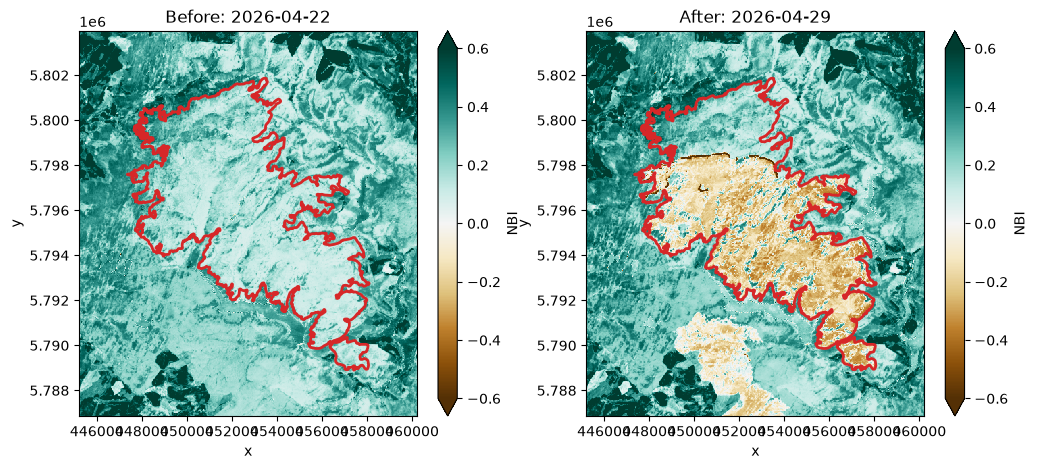

In [45]:
vmin, vmax = -.6, .6

fig, axes = plt.subplots(ncols=2, figsize=(12, 5))

ax = axes[0]
nbr_before.plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBI"})
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2) 
ax.set_title(f"Before: {before_date}")
ax.set_aspect('equal')

# Note: plots are drawn in the order they are called, so the fire outline will 
# need to be called after the image to appear on top.

ax = axes[1]

nbr_after.plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBI"})
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)
ax.set_title(f"After: {after_date}")
ax.set_aspect('equal')

plt.show()

## Sampling point data

Let's construct a simple geodataframe containing some point data:

In [57]:
burned_coords = 451742, 5796556
water_coords = 452411, 5791709
dry_veg_coords = 454607, 5800048
healthy_veg_coords = 459362, 5801403

points_gdf = gpd.GeoDataFrame(
    {"class": ["burned", "water", "dry_veg", "healthy_veg"]},
    geometry=[Point(burned_coords), Point(water_coords), Point(dry_veg_coords), Point(healthy_veg_coords)],
    crs="EPSG:32630"
)

points_gdf


,class,geometry
0,burned,POINT (451742 5796556)
1,water,POINT (452411 5791709)
2,dry_veg,POINT (454607 5800048)
3,healthy_veg,POINT (459362 5801403)


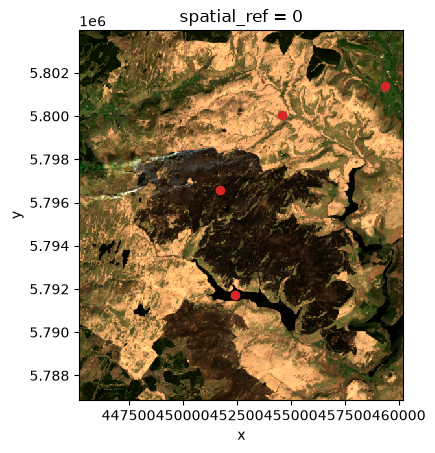

In [47]:
fig, ax = plt.subplots()

after_ds.sel(band=["red", "green", "blue"]).plot.imshow(ax=ax, robust=True)
points_gdf.plot(ax=ax, color="tab:red")

plt.show()

We have already seen how we can extract values at a single point [from an `xarray` timeseries in Week 4](../04/02-xarray.ipynb#extracting-time-series). To get values from a series of points, we just need to do a little more manipulation: turn the `x` and `y` coords into a list, and pass it to the `sel` function:

In [58]:
# Extract x and y coordinates from the GeoDataFrame and convert them to simple xarray DataArrays
x = xr.DataArray(points_gdf.geometry.x)
y = xr.DataArray(points_gdf.geometry.y)

# Sample from a dataarray
points_gdf['nbr_before'] = nbr_before.sel(x=x, y=y, method='nearest').values
points_gdf['nbr_after'] = nbr_after.sel(x=x, y=y, method='nearest').values

# Sample from a dataset by providing a band name
points_gdf['after_red_reflectance'] = after_ds.sel(band='red').sel(x=x, y=y, method='nearest').values

# Visualise new columns
points_gdf


,class,geometry,nbr_before,nbr_after,after_red_reflectance
0,burned,POINT (451742 5796556),0.166043,-0.013806,0.045052
1,water,POINT (452411 5791709),0.225756,0.216582,0.015353
2,dry_veg,POINT (454607 5800048),0.188484,0.160224,0.186568
3,healthy_veg,POINT (459362 5801403),0.693877,0.716191,0.033915


We can now use this geopandas dataframe to analyse and visualise data in the ways we have already learned:

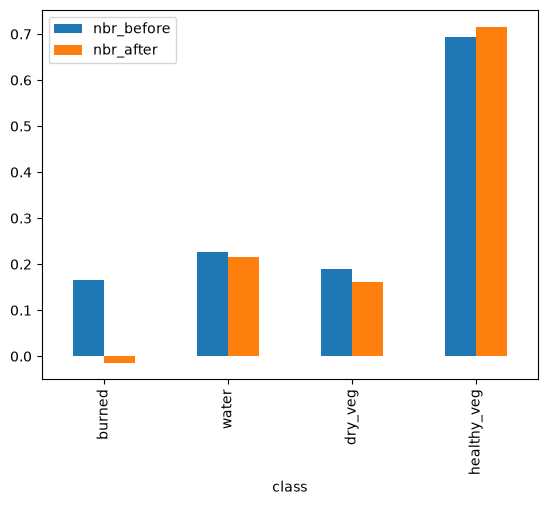

In [60]:
# Plot a bar chart for post-burn NBI values
points_gdf.plot.bar(x='class', y=['nbr_before', 'nbr_after'])

plt.show()

## Sampling line data

Sometimes, you may wish to plot a **transect** across a raster. This is often a straight line but may sometimes be (when chosen for a sensible reason) a curved line: for our purposes, we are going to use a simple line.

In [61]:
start_coords_x, start_coords_y = 447733, 5794202
end_coords_x, end_coords_y = 454507,5799442

transect_geom = LineString([(start_coords_x, start_coords_y), (end_coords_x, end_coords_y)])

transect_gdf = gpd.GeoDataFrame(geometry=[transect_geom], crs="EPSG:32630")

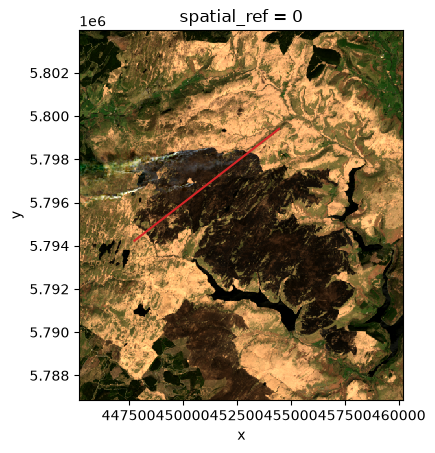

In [62]:
fig, ax = plt.subplots()

after_ds.sel(band=["red", "green", "blue"]).plot.imshow(ax=ax, robust=True)
transect_gdf.plot(ax=ax, color="tab:red")

plt.show()

The trick is that we not going to actually sample along a `LineString` datatype. Using `LineString.interpolate()` - which generates `Point`s at a specific distances along the line - we will turn the line into a series of regularly spaced points and sample those. As we have 30 m resolution data, we will stick with 30 m linespacing (there's no point in sampling at a higher resolution!).

In [82]:
# Generate regularly spaced points along the transect
spacing = 30  # metres (if using a projected CRS in metres)

# Calculate the distances along the transect at which to sample points
distances = np.arange(0, transect_geom.length, spacing)

# Create an empty list to hold the sampled points
transect_points = []

# Loop through the distances and generate points along the transect
for d in distances:

    # Generate a point at the specified distance along the transect
    point = transect_geom.interpolate(d)

    # Append the point to the list of transect points
    transect_points.append(point)

# Create a GeoDataFrame from the list of points
transect_sample_gdf = gpd.GeoDataFrame(
    {"distance": distances},
    geometry=transect_points,
    crs=transect_gdf.crs
)

# Visualise the sampled points along the transect
transect_sample_gdf

,distance,geometry
0,0.0,POINT (447733 5794202)
1,30.0,POINT (447756.729 5794220.356)
2,60.0,POINT (447780.458 5794238.711)
3,90.0,POINT (447804.187 5794257.067)
4,120.0,POINT (447827.917 5794275.422)
...,...,...
281,8430.0,POINT (454400.891 5799359.92)
282,8460.0,POINT (454424.62 5799378.275)
283,8490.0,POINT (454448.349 5799396.631)
284,8520.0,POINT (454472.078 5799414.986)


Now, we can sample as before:

In [83]:
# create new 'nbi_before' column in the GeoDataFrame, 
# with values sampled from the nbi_before dataarray.
transect_sample_gdf['nbr_before'] = nbr_before.sel(
    x = xr.DataArray(transect_sample_gdf.geometry.x),
    y = xr.DataArray(transect_sample_gdf.geometry.y),
    method='nearest'
)

# Same, but for ndi_after.
transect_sample_gdf['nbr_after'] = nbr_after.sel(
    x = xr.DataArray(transect_sample_gdf.geometry.x),
    y = xr.DataArray(transect_sample_gdf.geometry.y),
    method='nearest'
)

transect_sample_gdf

,distance,geometry,nbr_before,nbr_after
0,0.0,POINT (447733 5794202),0.309762,0.336718
1,30.0,POINT (447756.729 5794220.356),0.309845,0.307386
2,60.0,POINT (447780.458 5794238.711),0.288651,0.281133
3,90.0,POINT (447804.187 5794257.067),0.242495,0.262409
4,120.0,POINT (447827.917 5794275.422),0.230209,0.240906
...,...,...,...,...
281,8430.0,POINT (454400.891 5799359.92),0.393725,0.394014
282,8460.0,POINT (454424.62 5799378.275),0.416241,0.420278
283,8490.0,POINT (454448.349 5799396.631),0.408809,0.405541
284,8520.0,POINT (454472.078 5799414.986),0.361642,0.361841


Once again, we can now use usual `pandas` and `geopandas` techniques on this dataset:

In [85]:
# Calculate the change in NBR between the two time points and store it in a new column
transect_sample_gdf['nbr_change'] = transect_sample_gdf['nbr_after'] - transect_sample_gdf['nbr_before']

Text(0.5, 0, 'Distance along transect (m)')

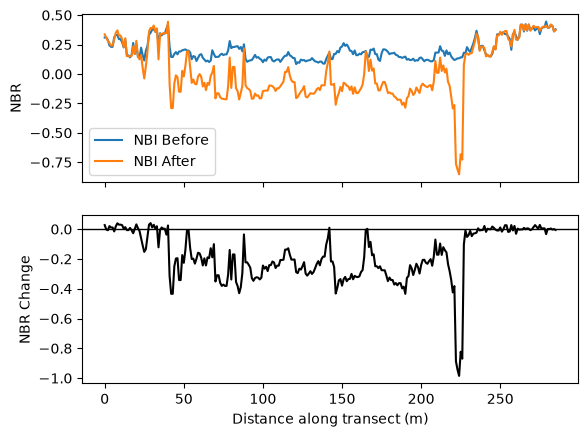

In [86]:
fig, axes = plt.subplots(nrows=2, sharex=True)

ax = axes[0]

transect_sample_gdf['nbr_before'].plot(ax=ax, label='NBI Before')
transect_sample_gdf['nbr_after'].plot(ax=ax, label='NBI After')

ax.legend()

ax.set_ylabel("NBR")

ax = axes[1]

ax.axhline(0, color='k', linestyle='-', linewidth=1)  # Add a horizontal line at y=0 for reference
transect_sample_gdf['nbr_change'].plot(ax=ax, color='k', label='NBR Change')

ax.set_ylabel("NBR Change")

ax.set_xlabel("Distance along transect (m)")

## Sampling polygon data (Zonal Statistics)

The final way we can consider sampling raster data is by sampling polygon data. A common term to describe this is gathering _zonal statistics_: i.e. we will be extracting statistical measures (mean, median, min, max, quantily, standard devition, sum, count, etc. etc.) over the polygons of interest.

As in our previous section, there is an 'in-house' way to do this that exclusively uses geopandas and rioxarray, or an option of drawing upon a community package that makes things simpler but adds another layer of dependencies to your project.

The simple way is to simply use the clip function and in-house xarray functions to get measures for a single region:

In [87]:
def get_mean_and_std(xda, gdf):

    xda_clip = xda.rio.clip(gdf.geometry, gdf.crs, drop=True, all_touched=True)

    mean_value = xda_clip.mean().item()
    std_value = xda_clip.std().item()

    return mean_value, std_value

before_mean, before_std = get_mean_and_std(nbr_before, fire_gdf)
after_mean, after_std = get_mean_and_std(nbr_after, fire_gdf)

Text(0.5, 1.0, 'NBR of Burned Area Before and After Fire')

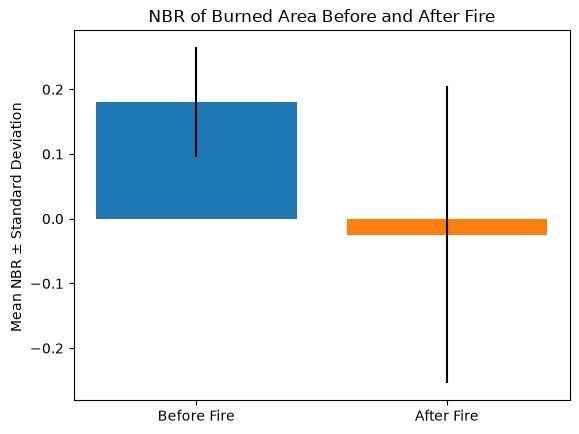

In [89]:
fig, ax =plt.subplots()

ax.bar(['Before Fire', 'After Fire'], [before_mean, after_mean], yerr=[before_std, after_std], color=['tab:blue', 'tab:orange'])
ax.set_ylabel("Mean NBR ± Standard Deviation ")
ax.set_title('NBR of Burned Area Before and After Fire')

This is easy when we just have one region, but needs a little more complexity when we have multiple regions of interest. For instance, let's return to our 'point' regions - rather than simply sampling one pixel (which might be subject to noise), we could gather the average of all pixels in a certain radius around a point. For instance, let's choose a buffer of 150 m (5 pixel radius).

In [90]:
points_gdf_buffer = points_gdf.copy()

points_gdf_buffer['geometry'] = points_gdf_buffer.geometry.buffer(150)  # Buffer of 150 meters / 5 pixels

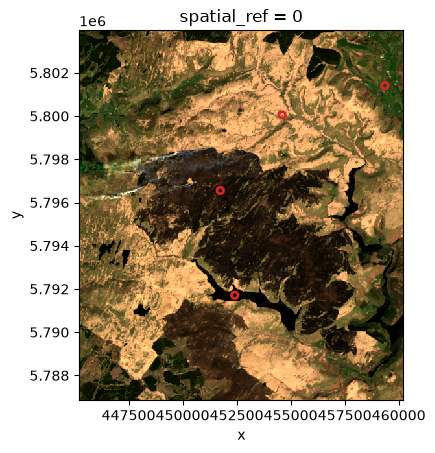

In [91]:
fig, ax = plt.subplots()

after_ds.sel(band=["red", "green", "blue"]).plot.imshow(ax=ax, robust=True)
points_gdf_buffer.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)

plt.show()

We can still do this in-house, by looping through each polygon individually:

In [92]:
# loop through polygons, getting mean and std of NBI before and after fire, storing in a list of dicts

mean_nbr_before_list = []
mean_nbr_after_list = []
std_nbr_before_list = []
std_nbr_after_list = []

# for i in length of points_gdf_buffer, get mean and std of nbi_before and nbi_after for each polygon
for i in range(len(points_gdf_buffer)):

    # Filter the points_gdf_buffer to get the current polygon
    row = points_gdf_buffer.iloc[[i]]

    mean_before, std_before = get_mean_and_std(nbr_before, row)
    mean_after, std_after = get_mean_and_std(nbr_after, row)

    mean_nbr_before_list.append(mean_before)
    mean_nbr_after_list.append(mean_after)
    std_nbr_before_list.append(std_before)
    std_nbr_after_list.append(std_after)

points_gdf_buffer['nbr_before_mean'] = mean_nbr_before_list
points_gdf_buffer['nbr_after_mean'] = mean_nbr_after_list

points_gdf_buffer['nbr_before_std'] = std_nbr_before_list
points_gdf_buffer['nbr_after_std'] = std_nbr_after_list

points_gdf_buffer

,class,geometry,nbr_before,nbr_after,after_red_reflectance,nbr_before_mean,nbr_after_mean,nbr_before_std,nbr_after_std
0,burned,"POLYGON ((451892 5796556, 451891.278 5796541.2...",0.166043,-0.013806,0.045052,0.135619,-0.230201,0.022970,0.076051
1,water,"POLYGON ((452561 5791709, 452560.278 5791694.2...",0.225756,0.216582,0.015353,0.241129,0.219284,0.022284,0.017524
2,dry_veg,"POLYGON ((454757 5800048, 454756.278 5800033.2...",0.188484,0.160224,0.186568,0.187243,0.187301,0.083304,0.083281
3,healthy_veg,"POLYGON ((459512 5801403, 459511.278 5801388.2...",0.693877,0.716191,0.033915,0.607456,0.647338,0.077731,0.076187


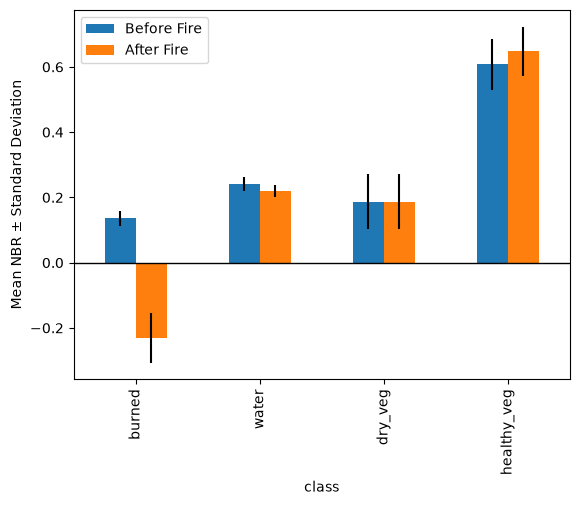

In [ ]:
# Plot a bar chart of the mean NBR values before and after the fire for each class, with error bars representing the standard deviation.

# Set up bar chart offset values
x = np.arange(len(points_gdf_buffer))
width = 0.35

# Begin plotting
fig, ax = plt.subplots()

points_gdf_buffer.plot.bar(x='class', y=['nbr_before_mean', 'nbr_after_mean'], yerr=[points_gdf_buffer['nbr_before_std'], points_gdf_buffer['nbr_after_std']], ax=ax, label=['Before Fire', 'After Fire'])

ax.set_ylabel("Mean NBR ± Standard Deviation")

# Add a horizontal line at y=0 for reference
ax.axhline(0, color='k', linewidth=1)  

ax.legend()

plt.show()

This is a nice result - it is clear that our self-identified burned region is the only one that displayed a significant (to 1 s.d.) difference between the two timesteps, showing that NBR is a good measure of detecting recently burned surface.

This is also quite a few lines of code to achieve such a result, and as ever there are Python packages that wrap this behaviour into a single handy module. There are multiple options within various packages such as `xarray-spatial`, but the most convenient [is called `exactextract`, the documentation for which can be found here](https://isciences.github.io/exactextract). As previously, don't bother going through all the hassle to install this (`conda install -c conda-forge exactextract`) unless you have serious plans to do this type of multi-polygon zonal statistics: however, it is here if you need it.

In [79]:
from exactextract import exact_extract

In [81]:
nbr_before_zonalstats = exact_extract(
    rast = nbr_before, 
    vec = points_gdf_buffer, 
    ops = ['mean', 'stdev'],  # select the operations you would like to calcualte.
    output = 'pandas'
    )

nbr_before_zonalstats

,mean,stdev
0,0.135384,0.023101
1,0.239443,0.021322
2,0.177700,0.074371
3,0.611450,0.076556


This pandas output can then easily be joined to your original dataframe. Note the results are the same as above - it's just wrapped into a nice function we don't have to worry about writing!

For further information about using `exactextract`, [examples can be found here](https://isciences.github.io/exactextract/examples_python.html) and the [available zonal statistics operations can be found here](https://isciences.github.io/exactextract/operations.html).

## Summary

We have seen how we can combine vector and raster data to extract spatially constrained data from raster datasets, in both point, line (transect), and polygon (zonal statistic) formats.